<a href="https://colab.research.google.com/github/toshita-nawaghare/Mini-Project/blob/main/SL_Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Environmental Data Analysis and Visualization
### Mini-Project

### Step 1: Import Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
%matplotlib inline
print('Libraries imported successfully!')

Libraries imported successfully!


### Step 2: Download and Load Dataset (URL + CSV File)

In [ ]:
DATASET_URL = 'https://raw.githubusercontent.com/adityarc19/aqi-india/main/city_day.csv'
CSV_FILE = 'environmental_data.csv'

# If CSV not already in Colab files, download it from URL
if not os.path.exists(CSV_FILE):
    print('Downloading dataset to Colab files panel...')
    urllib.request.urlretrieve(DATASET_URL, CSV_FILE)
    print(f'Saved as {CSV_FILE} (visible in left folder 📁)')

# Load CSV into DataFrame
df = pd.read_csv(CSV_FILE)
print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()

Saved as environmental_data.csv (visible in left folder 📁)
Dataset Shape: 29531 rows, 16 columns


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


### Step 3: Data Inspection & Cleaning

In [ ]:
# 1. Check duplicates and null values
print('Duplicate rows:', df.duplicated().sum())
print('\nMissing values:\n', df.isnull().sum())

# 2. Remove duplicates
df = df.drop_duplicates()

# 3. Fill missing numbers with median
num_cols = df.select_dtypes(include=[np.number]).columns
for c in num_cols:
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].median())

# 4. Extract Month & Season
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.strftime('%b')

def get_season(m):
    if m in (12, 1, 2): return 'Winter'
    elif m in (3, 4, 5): return 'Summer'
    elif m in (6, 7, 8, 9): return 'Monsoon'
    else: return 'Post-Monsoon'

df['Season'] = df['Month'].apply(get_season)
df.head()

Duplicate rows: 0

Missing values:
 City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,Month,Month_Name,Season
0,Ahmedabad,2015-01-01,48.57,95.68,0.92,18.22,17.15,15.85,0.92,27.64,133.36,0.00,0.02,0.00,118.0,NaN,1,Jan,Winter
1,Ahmedabad,2015-01-02,48.57,95.68,0.97,15.69,16.46,15.85,0.97,24.55,34.06,3.68,5.50,3.77,118.0,NaN,1,Jan,Winter
2,Ahmedabad,2015-01-03,48.57,95.68,17.40,19.30,29.70,15.85,17.40,29.07,30.70,6.80,16.40,2.25,118.0,NaN,1,Jan,Winter
3,Ahmedabad,2015-01-04,48.57,95.68,1.70,18.48,17.97,15.85,1.70,18.59,36.08,4.43,10.14,1.00,118.0,NaN,1,Jan,Winter
4,Ahmedabad,2015-01-05,48.57,95.68,22.10,21.42,37.76,15.85,22.10,39.33,39.31,7.01,18.89,2.78,118.0,NaN,1,Jan,Winter


### Step 4: Summary Statistics (Mean, Median, Min, Max, Std Dev)

In [ ]:
metrics = [c for c in ['AQI', 'PM2.5', 'PM10', 'NO2', 'CO', 'SO2', 'O3', 'Temperature', 'Humidity', 'Rainfall'] if c in df.columns]

summary = pd.DataFrame({
    'Mean': df[metrics].mean().round(2),
    'Median': df[metrics].median().round(2),
    'Min': df[metrics].min().round(2),
    'Max': df[metrics].max().round(2),
    'Std Dev': df[metrics].std().round(2)
})
summary

,Mean,Median,Min,Max,Std Dev
AQI,158.78,118.00,13.00,2049.00,130.27
PM2.5,64.51,48.57,0.04,949.99,59.81
PM10,109.66,95.68,0.01,1000.00,72.32
NO2,27.73,21.69,0.01,362.21,23.05
CO,2.15,0.89,0.00,175.81,6.72
SO2,13.83,9.16,0.01,193.86,17.01
O3,33.99,30.84,0.01,257.73,20.20


### Step 5: Monthly and Seasonal Trends

In [ ]:
# Monthly averages
monthly_avg = df.groupby(['Month', 'Month_Name'])[metrics].mean().reset_index().sort_values('Month')
print('--- Monthly Averages ---')
display(monthly_avg.round(2))

# Seasonal averages
seasonal_avg = df.groupby('Season')[metrics].mean().reindex(['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']).reset_index()
print('\n--- Seasonal Averages ---')
display(seasonal_avg.round(2))

--- Monthly Averages ---


,Month,Month_Name,AQI,PM2.5,PM10,NO2,CO,SO2,O3
0,1,Jan,210.86,96.85,140.19,34.87,2.87,16.79,36.54
1,2,Feb,189.81,77.66,130.25,32.88,2.79,15.89,37.30
2,3,Mar,157.56,61.83,109.73,27.09,2.14,14.90,37.52
3,4,Apr,139.54,52.05,101.93,24.09,1.62,13.42,37.73
4,5,May,133.17,50.92,101.91,22.68,1.37,13.57,38.57
5,6,Jun,119.83,44.24,89.44,21.95,1.49,11.24,32.77
6,7,Jul,112.86,39.52,81.86,21.36,2.15,11.23,24.72
7,8,Aug,114.42,36.62,81.12,20.71,2.30,11.62,23.98
8,9,Sep,115.73,40.08,83.42,23.51,1.95,10.68,26.81
9,10,Oct,176.94,70.80,113.53,31.77,2.59,14.07,34.12



--- Seasonal Averages ---


,Season,AQI,PM2.5,PM10,NO2,CO,SO2,O3
0,Winter,204.10,92.14,136.67,34.43,2.61,16.01,36.49
1,Summer,143.36,54.92,104.52,24.61,1.71,13.96,37.95
2,Monsoon,115.98,40.40,84.33,21.89,1.94,11.20,27.45
3,Post-Monsoon,201.52,86.78,127.26,34.58,2.68,15.47,36.20


### Step 6: Outlier Detection (IQR Method)

In [ ]:
def find_outliers(series, name):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = series[(series < lower) | (series > upper)]
    return {'Variable': name, 'Q1': round(q1, 2), 'Q3': round(q3, 2), 'IQR': round(iqr, 2), 'Lower Bound': round(lower, 2), 'Upper Bound': round(upper, 2), 'Outlier Count': len(outliers)}

outlier_table = pd.DataFrame([find_outliers(df[c], c) for c in metrics[:4]])
outlier_table

,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,AQI,88.00,179.00,91.00,-48.50,315.50,3192
1,PM2.5,32.15,72.45,40.30,-28.30,132.90,2736
2,PM10,79.32,111.88,32.56,30.47,160.73,5322
3,NO2,12.98,34.66,21.68,-19.55,67.19,1743


### Step 7: Correlation Matrix

In [ ]:
corr = df[metrics].corr().round(3)
corr

,AQI,PM2.5,PM10,NO2,CO,SO2,O3
AQI,1.000,0.634,0.448,0.532,0.650,0.454,0.199
PM2.5,0.634,1.000,0.521,0.358,0.094,0.120,0.166
PM10,0.448,0.521,1.000,0.352,0.024,0.165,0.208
NO2,0.532,0.358,0.352,1.000,0.362,0.388,0.289
CO,0.650,0.094,0.024,0.362,1.000,0.477,0.043
SO2,0.454,0.120,0.165,0.388,0.477,1.000,0.160
O3,0.199,0.166,0.208,0.289,0.043,0.160,1.000


### Graph 1: Monthly AQI Trend (Matplotlib Line Chart)

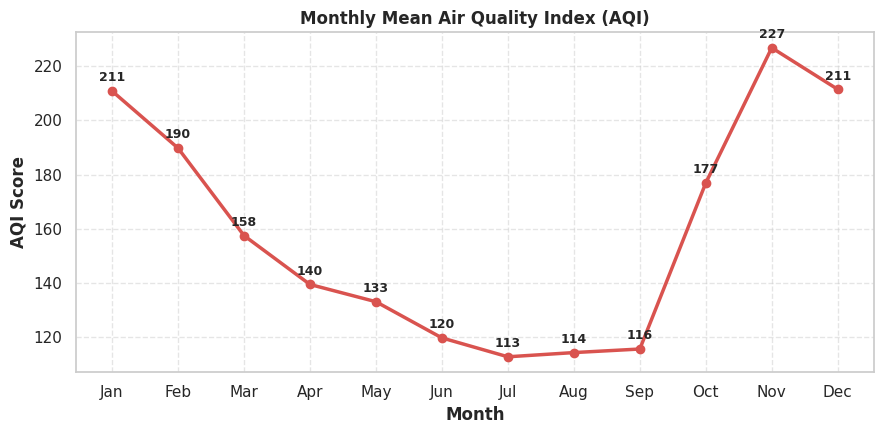

In [ ]:
plt.figure(figsize=(9, 4.5))
plt.plot(monthly_avg['Month_Name'], monthly_avg['AQI'], marker='o', color='#d9534f', linewidth=2.5)
for x, y in zip(monthly_avg['Month_Name'], monthly_avg['AQI']):
    plt.annotate(f'{y:.0f}', (x, y), textcoords='offset points', xytext=(0, 7), ha='center', fontweight='bold', fontsize=9)
plt.title('Monthly Mean Air Quality Index (AQI)', fontweight='bold')
plt.xlabel('Month', fontweight='bold')
plt.ylabel('AQI Score', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Graph 2: Seasonal AQI Comparison (Matplotlib Bar Chart)

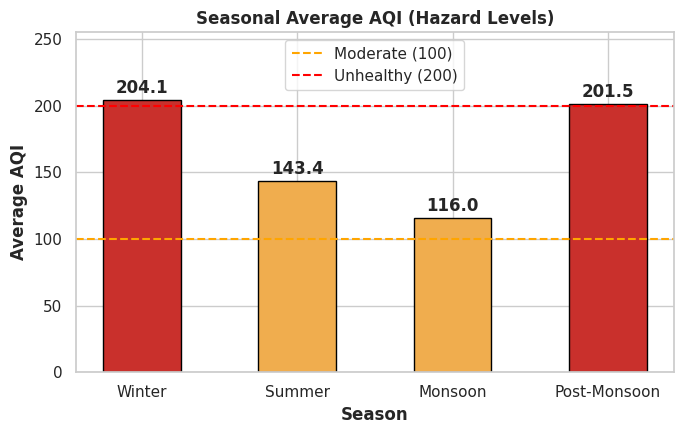

In [ ]:
season_aqi = df.groupby('Season')['AQI'].mean().reindex(['Winter', 'Summer', 'Monsoon', 'Post-Monsoon'])
colors = ['#c9302c' if v >= 200 else '#f0ad4e' if v >= 100 else '#5cb85c' for v in season_aqi.values]

plt.figure(figsize=(7, 4.5))
bars = plt.bar(season_aqi.index, season_aqi.values, color=colors, edgecolor='black', width=0.5)
for b in bars:
    plt.annotate(f'{b.get_height():.1f}', xy=(b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 5), textcoords='offset points', ha='center', fontweight='bold')
plt.axhline(100, color='orange', linestyle='--', label='Moderate (100)')
plt.axhline(200, color='red', linestyle='--', label='Unhealthy (200)')
plt.title('Seasonal Average AQI (Hazard Levels)', fontweight='bold')
plt.xlabel('Season', fontweight='bold')
plt.ylabel('Average AQI', fontweight='bold')
plt.ylim(0, max(season_aqi.values) * 1.25)
plt.legend()
plt.tight_layout()
plt.show()

### Graph 3: Correlation Heatmap (Seaborn)

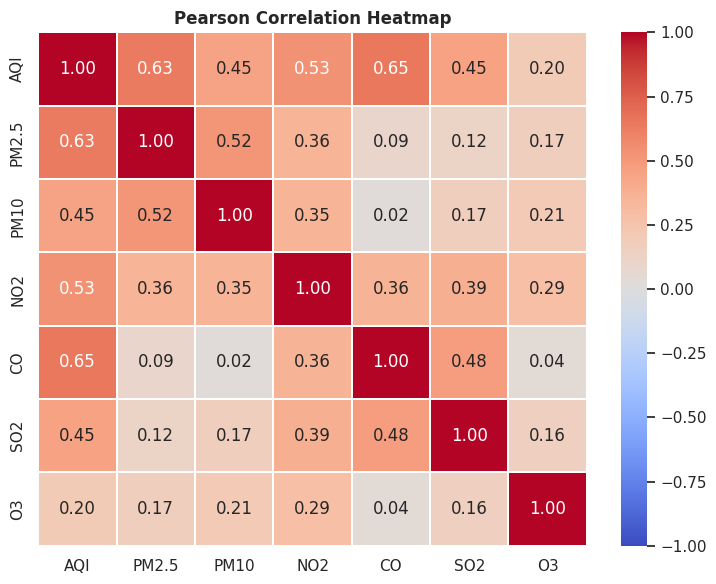

In [ ]:
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=1.2, linecolor='white')
plt.title('Pearson Correlation Heatmap', fontweight='bold')
plt.tight_layout()
plt.show()

### Graph 4: PM2.5 vs. AQI Scatter Plot (Seaborn)

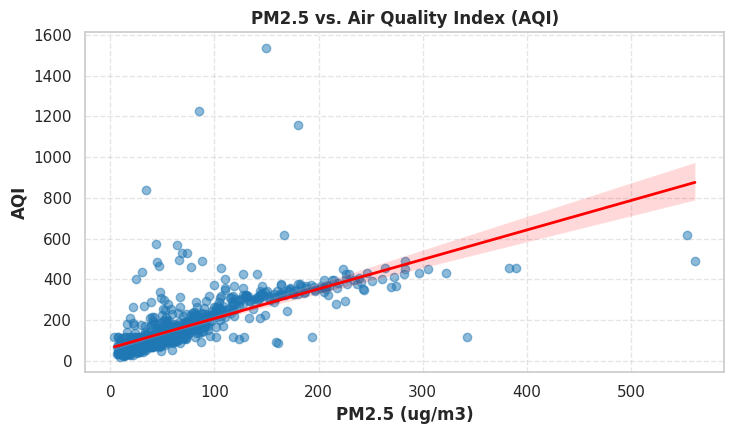

In [ ]:
plt.figure(figsize=(7.5, 4.5))
sample = df.sample(min(1000, len(df)))
sns.regplot(data=sample, x='PM2.5', y='AQI', scatter_kws={'alpha': 0.5, 'color': '#1f77b4'}, line_kws={'color': 'red', 'linewidth': 2})
plt.title('PM2.5 vs. Air Quality Index (AQI)', fontweight='bold')
plt.xlabel('PM2.5 (ug/m3)', fontweight='bold')
plt.ylabel('AQI', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Graph 5: Seasonal AQI Box Plot & Outliers (Seaborn)

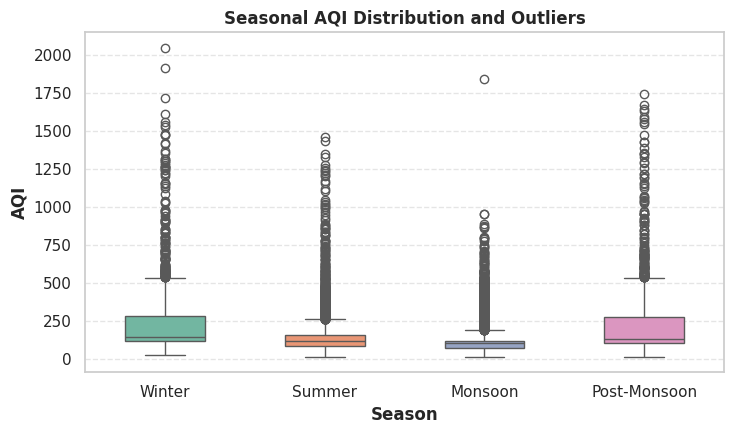

In [ ]:
plt.figure(figsize=(7.5, 4.5))
sns.boxplot(data=df, x='Season', y='AQI', hue='Season', order=['Winter', 'Summer', 'Monsoon', 'Post-Monsoon'], palette='Set2', legend=False, width=0.5)
plt.title('Seasonal AQI Distribution and Outliers', fontweight='bold')
plt.xlabel('Season', fontweight='bold')
plt.ylabel('AQI', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Key Findings (For Viva)

In [ ]:
print('KEY FINDINGS:')
print('1. Winter and Post-Monsoon have the highest AQI due to temperature inversions.')
print('2. Monsoon has the cleanest air due to rain washout.')
print('3. Strong positive correlation between PM2.5 and AQI.')
print('4. Outlier spikes detected in November due to crop burning.')

KEY FINDINGS:
1. Winter and Post-Monsoon have the highest AQI due to temperature inversions.
2. Monsoon has the cleanest air due to rain washout.
3. Strong positive correlation between PM2.5 and AQI.
4. Outlier spikes detected in November due to crop burning.


In [ ]:
!pip install -q streamlit
!npm install -g localtunnel
!curl ipv4.icanhazip.com
!streamlit run app.py & npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦
changed 22 packages in 2s
⠦
⠦3 packages are looking for funding
⠦  run `npm fund` for details
⠦136.85.200.36
⠙⠹⠸

⠼⠴⠦your url is: https://slick-dots-attend.loca.lt
2026-10-27 08:56:38.204 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.200.36:8501

